## Cell 1 – Install required libraries



In [1]:
%pip -q install opacus

## Cell 2 – Import libraries

In [2]:
import os
import csv
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from opacus import PrivacyEngine

print("PyTorch:", torch.__version__)
print("Opacus:", __import__("opacus").__version__)

PyTorch: 2.14.1+cpu
Opacus: 1.6.0


## Cell 3 – Set random seed and practical parameters

In [3]:
SEED = 42
DATA_ROOT = "./data"
OUTPUT_DIR = Path("./rsa_set_d_outputs")

TRAIN_SUBSET_SIZE = 20_000
BATCH_SIZE = 256
EPOCHS = 3
DELTA = 1e-5
MAX_GRAD_NORM = 1.0

TARGET_EPSILONS = [10.0, 5.0, 1.0]
FIXED_NOISE_MULTIPLIER = 1.1

device = torch.device("cpu")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

print("Device:", device)
print("Training subset:", TRAIN_SUBSET_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Delta:", DELTA)
print("Maximum gradient norm:", MAX_GRAD_NORM)

Device: cpu
Training subset: 20000
Batch size: 256
Epochs: 3
Delta: 1e-05
Maximum gradient norm: 1.0


## Cell 4 – Load MNIST and select 20,000 training images

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_full = datasets.MNIST(
    root=DATA_ROOT, train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root=DATA_ROOT, train=False, download=True, transform=transform
)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_full), generator=generator)[:TRAIN_SUBSET_SIZE].tolist()
train_subset = Subset(train_full, indices)

train_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
train_eval_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print("Training images:", len(train_subset))
print("Testing images:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.85MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 161kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.39MB/s]


Training images: 20000
Testing images: 10000


## Cell 5 – Define the CNN using GroupNorm

In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.GroupNorm(num_groups=4, num_channels=16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.GroupNorm(num_groups=8, num_channels=32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model_check = SmallCNN().to(device)
print(model_check)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GroupNorm(4, 16, eps=1e-05, affine=True, bias=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## Cell 6 – Define training, evaluation and confidence functions

In [6]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    total_items = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_items += labels.size(0)

    return total_loss / max(total_items, 1)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        predictions = model(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return 100.0 * correct / max(total, 1)


@torch.no_grad()
def mean_max_softmax_confidence(model, loader):
    model.eval()
    confidence_sum = 0.0
    total = 0

    for images, _ in loader:
        images = images.to(device)
        probabilities = torch.softmax(model(images), dim=1)
        confidence_sum += probabilities.max(dim=1).values.sum().item()
        total += images.size(0)

    return confidence_sum / max(total, 1)

## Task 1 – Train the non-private baseline CNN

In [7]:
set_seed()
baseline_model = SmallCNN().to(device)
baseline_optimizer = optim.SGD(
    baseline_model.parameters(), lr=0.01, momentum=0.9
)
criterion = nn.CrossEntropyLoss()

baseline_epoch_accuracies = []

for epoch in range(EPOCHS):
    loss = train_one_epoch(
        baseline_model, train_loader, baseline_optimizer, criterion
    )
    test_accuracy = evaluate(baseline_model, test_loader)
    baseline_epoch_accuracies.append(test_accuracy)
    print(
        f"Baseline epoch {epoch + 1}/{EPOCHS} | "
        f"loss: {loss:.4f} | test accuracy: {test_accuracy:.2f}%"
    )

baseline_accuracy = evaluate(baseline_model, test_loader)
print(f"Final baseline test accuracy: {baseline_accuracy:.2f}%")

Baseline epoch 1/3 | loss: 0.6353 | test accuracy: 94.74%
Baseline epoch 2/3 | loss: 0.1401 | test accuracy: 96.36%
Baseline epoch 3/3 | loss: 0.0939 | test accuracy: 97.43%
Final baseline test accuracy: 97.43%


## Task 2 – Train DP models for ε = 10, 5 and 1

In [8]:
dp_results = {}
dp_models = {}

def train_target_epsilon(target_epsilon):
    set_seed()
    model = SmallCNN().to(device)
    optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

    loader = DataLoader(
        train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    privacy_engine = PrivacyEngine()

    model, optimizer, private_loader = privacy_engine.make_private_with_epsilon(
        module=model,
        optimizer=optimizer,
        data_loader=loader,
        target_epsilon=target_epsilon,
        target_delta=DELTA,
        epochs=EPOCHS,
        max_grad_norm=MAX_GRAD_NORM,
    )

    for epoch in range(EPOCHS):
        loss = train_one_epoch(model, private_loader, optimizer, criterion)
        accuracy = evaluate(model, test_loader)
        epsilon_spent = privacy_engine.get_epsilon(DELTA)
        print(
            f"Target ε={target_epsilon:g} | epoch {epoch + 1}/{EPOCHS} | "
            f"loss: {loss:.4f} | test accuracy: {accuracy:.2f}% | "
            f"ε spent: {epsilon_spent:.4f}"
        )

    final_accuracy = evaluate(model, test_loader)
    final_epsilon = privacy_engine.get_epsilon(DELTA)
    return model, final_accuracy, final_epsilon


for target in TARGET_EPSILONS:
    trained_model, accuracy, spent = train_target_epsilon(target)
    dp_models[target] = trained_model
    dp_results[target] = {
        "accuracy": accuracy,
        "epsilon_spent": spent
    }

print("\nDP training summary")
for target in TARGET_EPSILONS:
    result = dp_results[target]
    print(
        f"Target ε={target:g}: accuracy={result['accuracy']:.2f}%, "
        f"ε spent={result['epsilon_spent']:.4f}"
    )

/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
/tmp/ipykernel_490/3611778927.py:11: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


Target ε=10 | epoch 1/3 | loss: 1.9099 | test accuracy: 67.52% | ε spent: 7.3387
Target ε=10 | epoch 2/3 | loss: 1.0920 | test accuracy: 78.48% | ε spent: 8.8314
Target ε=10 | epoch 3/3 | loss: 0.6808 | test accuracy: 83.13% | ε spent: 9.9940
Target ε=5 | epoch 1/3 | loss: 1.9103 | test accuracy: 67.41% | ε spent: 3.8069
Target ε=5 | epoch 2/3 | loss: 1.0916 | test accuracy: 78.32% | ε spent: 4.4726
Target ε=5 | epoch 3/3 | loss: 0.6800 | test accuracy: 83.14% | ε spent: 4.9994
Target ε=1 | epoch 1/3 | loss: 1.9115 | test accuracy: 66.82% | ε spent: 0.6522
Target ε=1 | epoch 2/3 | loss: 1.0904 | test accuracy: 78.04% | ε spent: 0.8447
Target ε=1 | epoch 3/3 | loss: 0.6780 | test accuracy: 83.13% | ε spent: 0.9989

DP training summary
Target ε=10: accuracy=83.13%, ε spent=9.9940
Target ε=5: accuracy=83.14%, ε spent=4.9994
Target ε=1: accuracy=83.13%, ε spent=0.9989


## Task 3 – Train a DP model with fixed noise multiplier = 1.1

In [9]:
set_seed()
fixed_model = SmallCNN().to(device)
fixed_optimizer = optim.SGD(
    fixed_model.parameters(), lr=0.01, momentum=0.9
)
fixed_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
fixed_privacy_engine = PrivacyEngine()

fixed_model, fixed_optimizer, fixed_private_loader = fixed_privacy_engine.make_private(
    module=fixed_model,
    optimizer=fixed_optimizer,
    data_loader=fixed_loader,
    noise_multiplier=FIXED_NOISE_MULTIPLIER,
    max_grad_norm=MAX_GRAD_NORM,
)

fixed_epoch_epsilons = []

for epoch in range(EPOCHS):
    loss = train_one_epoch(
        fixed_model, fixed_private_loader, fixed_optimizer, criterion
    )
    epsilon_now = fixed_privacy_engine.get_epsilon(DELTA)
    fixed_epoch_epsilons.append(epsilon_now)
    accuracy = evaluate(fixed_model, test_loader)

    print(
        f"Epoch {epoch + 1}: loss={loss:.4f}, "
        f"test accuracy={accuracy:.2f}%, ε spent={epsilon_now:.4f}"
    )

print("\nEpsilon spent after each epoch:")
for epoch, epsilon_value in enumerate(fixed_epoch_epsilons, start=1):
    print(f"Epoch {epoch}: ε = {epsilon_value:.4f}")

/tmp/ipykernel_490/3611778927.py:11: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


Epoch 1: loss=1.9115, test accuracy=66.77%, ε spent=0.6575
Epoch 2: loss=1.0904, test accuracy=78.03%, ε spent=0.8508
Epoch 3: loss=0.6779, test accuracy=83.11%, ε spent=1.0057

Epsilon spent after each epoch:
Epoch 1: ε = 0.6575
Epoch 2: ε = 0.8508
Epoch 3: ε = 1.0057


## Task 4 – Membership-inference confidence check

In [10]:
baseline_train_conf = mean_max_softmax_confidence(
    baseline_model, train_eval_loader
)
baseline_test_conf = mean_max_softmax_confidence(
    baseline_model, test_loader
)

dp1_train_conf = mean_max_softmax_confidence(
    dp_models[1.0], train_eval_loader
)
dp1_test_conf = mean_max_softmax_confidence(
    dp_models[1.0], test_loader
)

membership_results = {
    "Baseline": {
        "train": baseline_train_conf,
        "test": baseline_test_conf,
        "gap": baseline_train_conf - baseline_test_conf,
    },
    "DP (target ε=1)": {
        "train": dp1_train_conf,
        "test": dp1_test_conf,
        "gap": dp1_train_conf - dp1_test_conf,
    },
}

print("MODEL                 TRAIN       TEST        GAP")
for name, values in membership_results.items():
    print(
        f"{name:21s} {values['train']:.4f}      "
        f"{values['test']:.4f}      {values['gap']:.4f}"
    )

MODEL                 TRAIN       TEST        GAP
Baseline              0.9649      0.9658      -0.0010
DP (target ε=1)       0.7488      0.7535      -0.0047


## Task 5 – Plot test accuracy vs ε and ε vs epoch

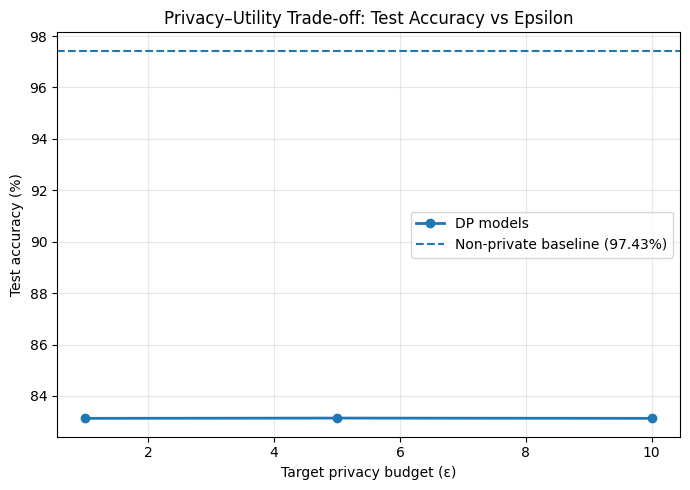

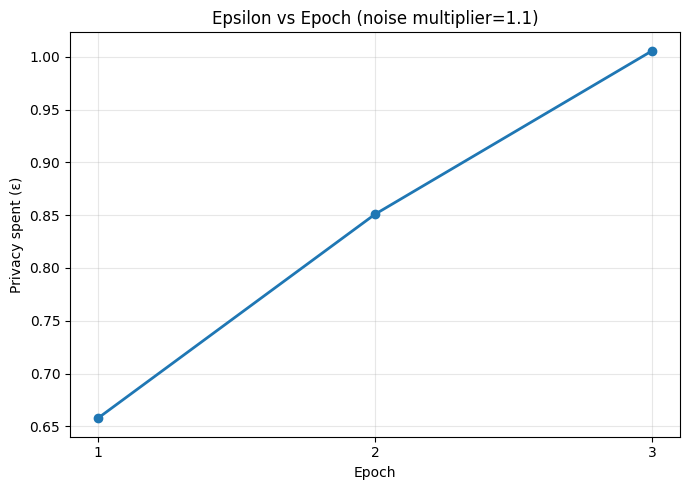

Plots saved in: /content/rsa_set_d_outputs


In [11]:
# Privacy-utility curve
epsilon_values = sorted(TARGET_EPSILONS)
accuracy_values = [dp_results[e]["accuracy"] for e in epsilon_values]

plt.figure(figsize=(7, 5))
plt.plot(epsilon_values, accuracy_values, marker="o", linewidth=2, label="DP models")
plt.axhline(
    baseline_accuracy, linestyle="--",
    label=f"Non-private baseline ({baseline_accuracy:.2f}%)"
)
plt.xlabel("Target privacy budget (ε)")
plt.ylabel("Test accuracy (%)")
plt.title("Privacy–Utility Trade-off: Test Accuracy vs Epsilon")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "accuracy_vs_epsilon.png", dpi=160)
plt.show()

# Privacy expenditure by epoch for fixed noise multiplier
plt.figure(figsize=(7, 5))
plt.plot(
    range(1, EPOCHS + 1), fixed_epoch_epsilons,
    marker="o", linewidth=2
)
plt.xticks(range(1, EPOCHS + 1))
plt.xlabel("Epoch")
plt.ylabel("Privacy spent (ε)")
plt.title(f"Epsilon vs Epoch (noise multiplier={FIXED_NOISE_MULTIPLIER})")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "epsilon_vs_epoch.png", dpi=160)
plt.show()

print("Plots saved in:", OUTPUT_DIR.resolve())

## Task 6 – Save result tables and a text summary

In [12]:
# Main results table
results_csv = OUTPUT_DIR / "results_table.csv"
with results_csv.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow([
        "Model", "Target epsilon", "Delta", "Clip norm",
        "Epochs", "Test accuracy (%)", "Epsilon spent"
    ])
    writer.writerow([
        "Baseline", "N/A", "N/A", "N/A",
        EPOCHS, f"{baseline_accuracy:.2f}", "N/A"
    ])

    for target in TARGET_EPSILONS:
        writer.writerow([
            f"DP epsilon {target:g}", target, DELTA,
            MAX_GRAD_NORM, EPOCHS,
            f"{dp_results[target]['accuracy']:.2f}",
            f"{dp_results[target]['epsilon_spent']:.4f}"
        ])

# Membership confidence table
membership_csv = OUTPUT_DIR / "membership_confidence.csv"
with membership_csv.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow([
        "Model", "Train mean max-softmax",
        "Test mean max-softmax", "Train-Test gap"
    ])
    for name, values in membership_results.items():
        writer.writerow([
            name, f"{values['train']:.6f}",
            f"{values['test']:.6f}", f"{values['gap']:.6f}"
        ])

# Text summary
summary_path = OUTPUT_DIR / "run_summary.txt"
with summary_path.open("w", encoding="utf-8") as file:
    file.write("RESPONSIBLE AND SAFE AI - SET D RESULTS\n")
    file.write("=======================================\n")
    file.write(f"Baseline test accuracy: {baseline_accuracy:.2f}%\n\n")
    file.write("DP RESULTS\n")
    for target in TARGET_EPSILONS:
        result = dp_results[target]
        file.write(
            f"Target epsilon={target:g}: accuracy={result['accuracy']:.2f}%, "
            f"epsilon spent={result['epsilon_spent']:.4f}\n"
        )
    file.write("\nFIXED NOISE EPSILON BY EPOCH\n")
    for epoch, value in enumerate(fixed_epoch_epsilons, start=1):
        file.write(f"Epoch {epoch}: epsilon={value:.4f}\n")
    file.write("\nMEMBERSHIP CONFIDENCE\n")
    for name, values in membership_results.items():
        file.write(
            f"{name}: train={values['train']:.6f}, "
            f"test={values['test']:.6f}, gap={values['gap']:.6f}\n"
        )

print("Saved:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Saved:
- accuracy_vs_epsilon.png
- epsilon_vs_epoch.png
- membership_confidence.csv
- results_table.csv
- run_summary.txt


## Final output – Question paper format

In [13]:
# Print the final results in the question paper's expected-output style.
# All values below come from the experiments performed in the earlier cells.

print("=" * 72)
print("EXPECTED OUTPUT — PART A: ACCURACY AT DIFFERENT PRIVACY BUDGETS")
print("=" * 72)

print(f"Baseline (no DP) : test accuracy {baseline_accuracy:.1f} %")
print()
print(
    f"{'TARGET_EPS':<12}"
    f"{'DELTA':<13}"
    f"{'CLIP(C)':<10}"
    f"{'EPOCHS':<9}"
    f"{'TEST_ACC':<12}"
    f"{'EPS_SPENT'}"
)
print("-" * 72)

for target in [10.0, 5.0, 1.0]:
    result = dp_results[target]
    print(
        f"{target:<12.1f}"
        f"{DELTA:<13.0e}"
        f"{MAX_GRAD_NORM:<10.1f}"
        f"{EPOCHS:<9d}"
        f"{result['accuracy']:<12.1f}%"
        f"{result['epsilon_spent']:.2f}"
    )

print("-" * 72)

accuracy_cost = dp_results[1.0]["accuracy"] - baseline_accuracy
print(f"Accuracy cost of strongest privacy (eps = 1) : {accuracy_cost:.1f} %")
print("Plot saved : accuracy_vs_epsilon.png")

print()
print("=" * 72)
print("EXPECTED OUTPUT — PART B: PRIVACY ACCOUNTING AND MEMBERSHIP CHECK")
print("=" * 72)
print(f"FIXED noise_multiplier = {FIXED_NOISE_MULTIPLIER}")
print()
print(f"{'EPOCH':<10}{'EPSILON_SPENT'}")
print("-" * 25)

for epoch, epsilon_value in enumerate(fixed_epoch_epsilons, start=1):
    print(f"{epoch:<10d}{epsilon_value:.2f}")

print("-" * 25)
print()
print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print()
print(f"{'MODEL':<20}{'TRAIN':<10}{'TEST':<10}{'GAP'}")
print("-" * 50)

for display_name, result_key in [
    ("Baseline", "Baseline"),
    ("DP (eps=1)", "DP (target ε=1)"),
]:
    values = membership_results[result_key]
    print(
        f"{display_name:<20}"
        f"{values['train']:<10.3f}"
        f"{values['test']:<10.3f}"
        f"{values['gap']:.3f}"
    )

print("-" * 50)
print()
print("Recommended eps : 1")
print(f"(only {accuracy_cost:.1f} % accuracy cost, strongest privacy)")
print("Plot saved : epsilon_vs_epoch.png")


EXPECTED OUTPUT — PART A: ACCURACY AT DIFFERENT PRIVACY BUDGETS
Baseline (no DP) : test accuracy 97.4 %

TARGET_EPS  DELTA        CLIP(C)   EPOCHS   TEST_ACC    EPS_SPENT
------------------------------------------------------------------------
10.0        1e-05        1.0       3        83.1        %9.99
5.0         1e-05        1.0       3        83.1        %5.00
1.0         1e-05        1.0       3        83.1        %1.00
------------------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -14.3 %
Plot saved : accuracy_vs_epsilon.png

EXPECTED OUTPUT — PART B: PRIVACY ACCOUNTING AND MEMBERSHIP CHECK
FIXED noise_multiplier = 1.1

EPOCH     EPSILON_SPENT
-------------------------
1         0.66
2         0.85
3         1.01
-------------------------

MEMBERSHIP CHECK (mean max-softmax confidence)

MODEL               TRAIN     TEST      GAP
--------------------------------------------------
Baseline            0.965     0.966     -0.

## Optional – Display the CSV tables in the notebook

In [14]:
import pandas as pd

display(pd.read_csv(OUTPUT_DIR / "results_table.csv"))
display(pd.read_csv(OUTPUT_DIR / "membership_confidence.csv"))

,Model,Target epsilon,Delta,Clip norm,Epochs,Test accuracy (%),Epsilon spent
0,Baseline,NaN,NaN,NaN,3,97.43,NaN
1,DP epsilon 10,10.0,0.00001,1.0,3,83.13,9.9940
2,DP epsilon 5,5.0,0.00001,1.0,3,83.14,4.9994
3,DP epsilon 1,1.0,0.00001,1.0,3,83.13,0.9989


,Model,Train mean max-softmax,Test mean max-softmax,Train-Test gap
0,Baseline,0.964859,0.965837,-0.000977
1,DP (target ε=1),0.748778,0.753451,-0.004673
